# SGD vs. IDBD vs. IDBD mit β-Momentum

Momentum wirkt **nur auf die Log-Lernraten**: `v = μ*v - grad*h`, `β += meta_lr*v`. Gewichte und h werden danach nach der bisherigen IDBD-Regel aktualisiert. Das ist eine heuristische Meta-Update-Variante, keine exakte Differentiation durch Momentum.

Alle drei Modelle sehen dieselben Batches und starten mit identischen Gewichten. Nur Feature 0 ist relevant; alle übrigen Features sind Distraktoren (unabhängige Bernoulli(0,01)-Variablen). Das Target enthält zusätzlich Gauß-Rauschen mit Varianz 5 und seltene Impulse. Distraktor-Gewichte sollten gegen 0 gehen, das hilfreiche Gewicht gegen 1.

Wir betrachten RMS, einzelne Gewichte, die Verteilung und einzelne Verläufe der Lernraten sowie Fehler auf einem unabhängigen sauberen Teststream. Schnell sinkende Lernraten allein sind kein Erfolg: Sie können falsche Gewichte einfrieren.

In [ ]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
if not (root / 'src' / 'optim').is_dir():
    raise RuntimeError('Notebook vom Repository-Root oder aus notebooks/ starten.')
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import copy
from collections import deque
from itertools import islice

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader

from src.data import DataStream
from src.optim import IDBD, IDBDMomentum

plt.rcParams.update({'figure.figsize': (12, 5), 'axes.grid': True})


In [10]:
SEED = 1234
INPUT_DIM = 128
ITERATIONS = 2**18
BATCH_SIZE = 32
INITIAL_LR = 0.01
META_LR = 0.1
BETA_MOMENTUM = 0.9
RECORD_EVERY = 50  # Vollständige Gewichte/LRs nur alle N Updates speichern.
TEST_ITERATIONS = 100
TEST_BATCH_SIZE = 128
RUN_MATCHED_META_LR = False  # Optionaler zweiter, vollständig frischer Vergleich.

# Momentum verstärkt konstante Meta-Gradienten langfristig um 1/(1-μ).
# Im Hauptvergleich bleibt meta_lr gleich; μ=0.9 bedeutet ca. Faktor 10.
# Der optionale Vergleich reduziert NUR die Momentum-meta_lr um (1-μ).
assert INPUT_DIM >= 2
assert ITERATIONS > 0 and BATCH_SIZE > 0 and RECORD_EVERY > 0
assert TEST_ITERATIONS > 0 and TEST_BATCH_SIZE > 0
assert 0 <= BETA_MOMENTUM < 1


In [11]:
def rates_for(model, optimizer):
    if isinstance(optimizer, IDBD):
        state = optimizer.state.get(model.weight, {})
        if 'beta' in state:
            return state['beta'].exp().flatten()
        lr = optimizer.param_groups[0]['initial_lr']
    else:
        lr = optimizer.param_groups[0]['lr']
    return torch.full_like(model.weight.flatten(), float(lr))


@torch.no_grad()
def test_models(models, seed, input_dim, iterations, batch_size):
    totals = {name: np.zeros(5) for name in (*models, 'Zero')}
    loader = DataLoader(DataStream(input_dim=input_dim, seed=seed),
                        batch_size=batch_size, num_workers=0,
                        generator=torch.Generator().manual_seed(seed))
    for x, noisy_y, clean_y in islice(loader, iterations):
        active = clean_y == 1
        for name in totals:
            prediction = models[name](x).flatten() if name != 'Zero' else torch.zeros_like(clean_y)
            noisy_error = prediction.double() - noisy_y.double()
            clean_error = prediction.double() - clean_y.double()
            totals[name] += [len(x), active.sum().item(), noisy_error.square().sum().item(),
                             clean_error.square().sum().item(),
                             clean_error[active].square().sum().item()]
    rows = []
    for name, (count, active_count, noisy_sse, clean_sse, active_sse) in totals.items():
        rows.append({'model': name, 'test_noisy_mse': noisy_sse / count,
                     'test_clean_mse': clean_sse / count,
                     'test_active_clean_mse': active_sse / active_count if active_count else np.nan})
    return pd.DataFrame(rows).set_index('model')


def compare(*, seed, input_dim, iterations, batch_size, initial_lr, meta_lr,
            beta_momentum, momentum_meta_lr, record_every,
            test_iterations, test_batch_size):
    # Kein MLflow und kein Import von src.main (dies würde den Plot-Backend ändern).
    # RNG-Zustand außerhalb des Experiments nicht verändern.
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        initial_model = nn.Linear(input_dim, 1, bias=False)
    models = {name: copy.deepcopy(initial_model)
              for name in ('SGD', 'IDBD', 'IDBD + β-momentum')}
    optimizers = {
        'SGD': torch.optim.SGD(models['SGD'].parameters(), lr=initial_lr),
        'IDBD': IDBD(models['IDBD'].parameters(), initial_lr=initial_lr, meta_lr=meta_lr),
        'IDBD + β-momentum': IDBDMomentum(models['IDBD + β-momentum'].parameters(),
            initial_lr=initial_lr, meta_lr=momentum_meta_lr, beta_momentum=beta_momentum),
    }
    trace = {name: {'weights': [], 'rates': [], 'loss_ma_200': []} for name in models}
    recent_losses = {name: deque(maxlen=200) for name in models}
    steps = []

    @torch.no_grad()
    def record(step):
        steps.append(step)
        for name, model in models.items():
            trace[name]['weights'].append(model.weight.flatten().cpu().numpy().copy())
            trace[name]['rates'].append(rates_for(model, optimizers[name]).cpu().numpy().copy())
            losses = recent_losses[name]
            trace[name]['loss_ma_200'].append(np.mean(losses) if losses else np.nan)

    record(0)
    loader = DataLoader(DataStream(input_dim=input_dim, seed=seed),
                        batch_size=batch_size, num_workers=0,
                        generator=torch.Generator().manual_seed(seed))
    for step, (x, noisy_y, _) in enumerate(islice(loader, iterations), start=1):
        for name, model in models.items():
            optimizer = optimizers[name]
            optimizer.zero_grad(set_to_none=True)
            prediction = model(x).flatten()
            loss = 0.5 * (prediction - noisy_y).square().mean()
            if not torch.isfinite(loss).item():
                raise FloatingPointError(f'{name}: non-finite loss at update {step}')
            loss.backward()
            optimizer.step(x) if isinstance(optimizer, IDBD) else optimizer.step()
            with torch.no_grad():
                rates = rates_for(model, optimizer)
                state = optimizer.state.get(model.weight, {})
                finite = all(torch.isfinite(value).all().item() for value in state.values()
                             if isinstance(value, torch.Tensor))
                if not (finite and torch.isfinite(model.weight).all().item()
                        and torch.isfinite(rates).all().item() and (rates > 0).all().item()):
                    raise FloatingPointError(f'{name}: invalid weights/LRs/state at update {step}; '
                                             'try a smaller meta_lr or beta_momentum')
            recent_losses[name].append(loss.item())
        if step % record_every == 0 or step == iterations:
            record(step)
        if step % max(1, iterations // 10) == 0 or step == iterations:
            print(f'{step}/{iterations} updates')
    for values in trace.values():
        for key in values:
            values[key] = np.asarray(values[key])
    metrics = test_models(models, seed + 1, input_dim, test_iterations, test_batch_size)
    for name, values in trace.items():
        weights, rates = values['weights'][-1], values['rates'][-1]
        metrics.loc[name, 'useful_weight'] = weights[0]
        metrics.loc[name, 'useful_lr'] = rates[0]
        metrics.loc[name, 'distractor_weight_rms'] = np.sqrt(np.mean(weights[1:] ** 2))
        metrics.loc[name, 'distractor_lr_mean'] = rates[1:].mean()
        metrics.loc[name, 'distractor_lr_median'] = np.median(rates[1:])
    return {'models': models, 'optimizers': optimizers, 'trace': trace,
            'steps': np.asarray(steps), 'examples': np.asarray(steps) * batch_size,
            'metrics': metrics}


In [12]:
config = dict(seed=SEED, input_dim=INPUT_DIM, iterations=ITERATIONS, batch_size=BATCH_SIZE,
              initial_lr=INITIAL_LR, meta_lr=META_LR, beta_momentum=BETA_MOMENTUM,
              record_every=RECORD_EVERY, test_iterations=TEST_ITERATIONS,
              test_batch_size=TEST_BATCH_SIZE)
results = compare(**config, momentum_meta_lr=META_LR)
display(results['metrics'])


26214/262144 updates
52428/262144 updates
78642/262144 updates
104856/262144 updates
131070/262144 updates
157284/262144 updates
183498/262144 updates
209712/262144 updates
235926/262144 updates
262140/262144 updates
262144/262144 updates


,test_noisy_mse,test_clean_mse,test_active_clean_mse,useful_weight,useful_lr,distractor_weight_rms,distractor_lr_mean,distractor_lr_median
model,,,,,,,,
SGD,5.098178,0.000910,0.002278,0.964651,0.010000,0.026384,0.010000,0.010000
IDBD,5.098260,0.000856,0.004664,0.939953,0.026975,0.025132,0.009103,0.009095
IDBD + β-momentum,5.097214,0.000443,0.001452,0.968367,0.008178,0.018291,0.005199,0.005084
Zero,5.116566,0.011406,1.000000,NaN,NaN,NaN,NaN,NaN


## Distraktor-Übersicht und hilfreiches Feature

Das Lernraten-Band zeigt das 10.–90. Perzentil **über Features**, kein Konfidenzintervall. Die Mittelwerte können von wenigen großen Lernraten dominiert werden; deshalb zusätzlich Median und Quantile. Alle Gewichte und Lernraten sind post-update, inklusive gemeinsamer Initialisierung bei Update 0.

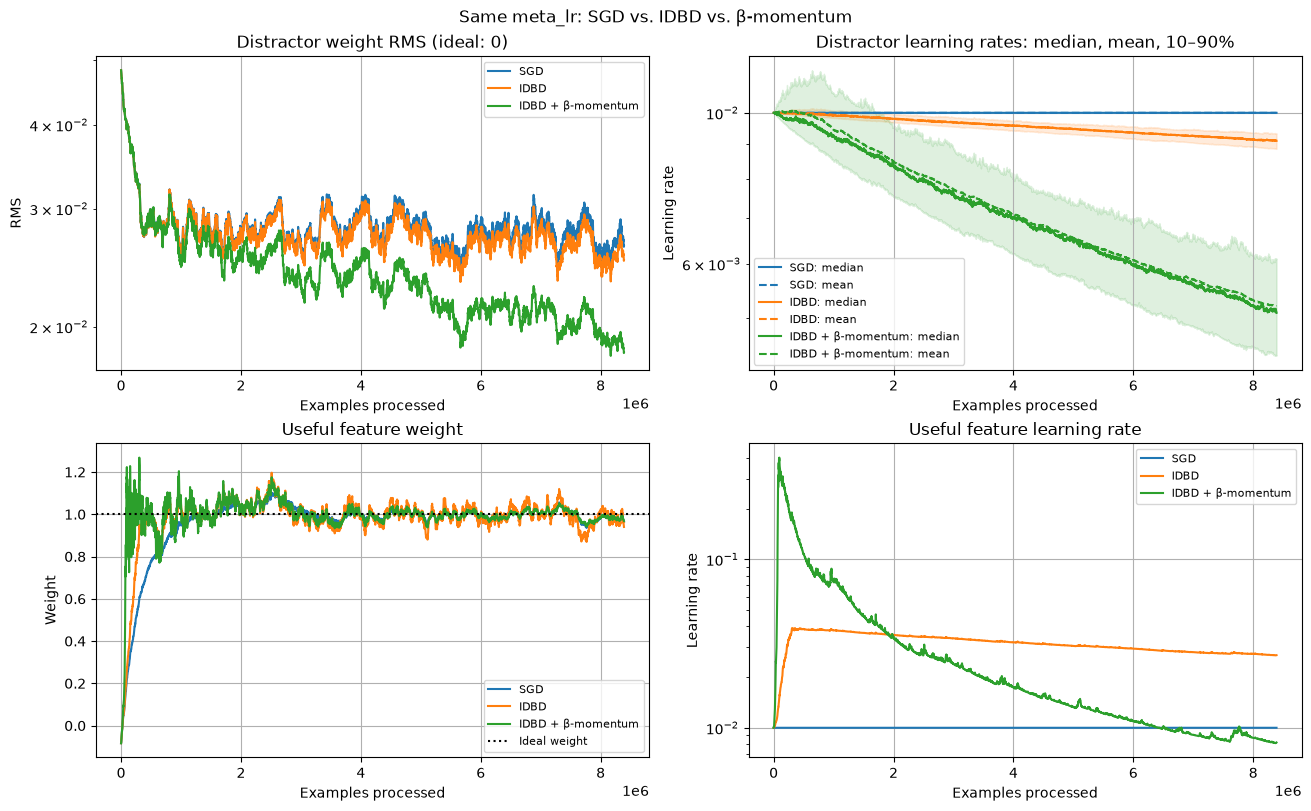

In [13]:
def plot_overview(result, title):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
    for name, values in result['trace'].items():
        weights, rates = values['weights'], values['rates']
        examples = result['examples']
        axes[0, 0].plot(examples, np.sqrt(np.mean(weights[:, 1:] ** 2, axis=1)), label=name)
        q10, median, q90 = np.quantile(rates[:, 1:], [0.1, 0.5, 0.9], axis=1)
        line, = axes[0, 1].plot(examples, median, label=f'{name}: median')
        axes[0, 1].fill_between(examples, q10, q90, color=line.get_color(), alpha=0.15)
        axes[0, 1].plot(examples, rates[:, 1:].mean(axis=1), '--',
                        color=line.get_color(), label=f'{name}: mean')
        axes[1, 0].plot(examples, weights[:, 0], label=name)
        axes[1, 1].plot(examples, rates[:, 0], label=name)
    axes[0, 0].set(title='Distractor weight RMS (ideal: 0)', ylabel='RMS', yscale='log')
    axes[0, 1].set(title='Distractor learning rates: median, mean, 10–90%',
                   ylabel='Learning rate', yscale='log')
    axes[1, 0].set(title='Useful feature weight', ylabel='Weight')
    axes[1, 0].axhline(1, color='black', linestyle=':', label='Ideal weight')
    axes[1, 1].set(title='Useful feature learning rate', ylabel='Learning rate', yscale='log')
    for ax in axes.flat:
        ax.set_xlabel('Examples processed')
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.show()

plot_overview(results, 'Same meta_lr: SGD vs. IDBD vs. β-momentum')


## Einzelne Distraktoren

In allen drei Modellen werden dieselben Feature-Indizes gezeigt (erste sechs Distraktoren, ohne Auswahl nach Ergebnis). Die Gewichte sind vorzeichenbehaftet, die Lernraten logarithmisch. Momentum kann β auch bei einem aktuell inaktiven Feature weiterbewegen, solange dessen Buffer nicht abgeklungen ist.

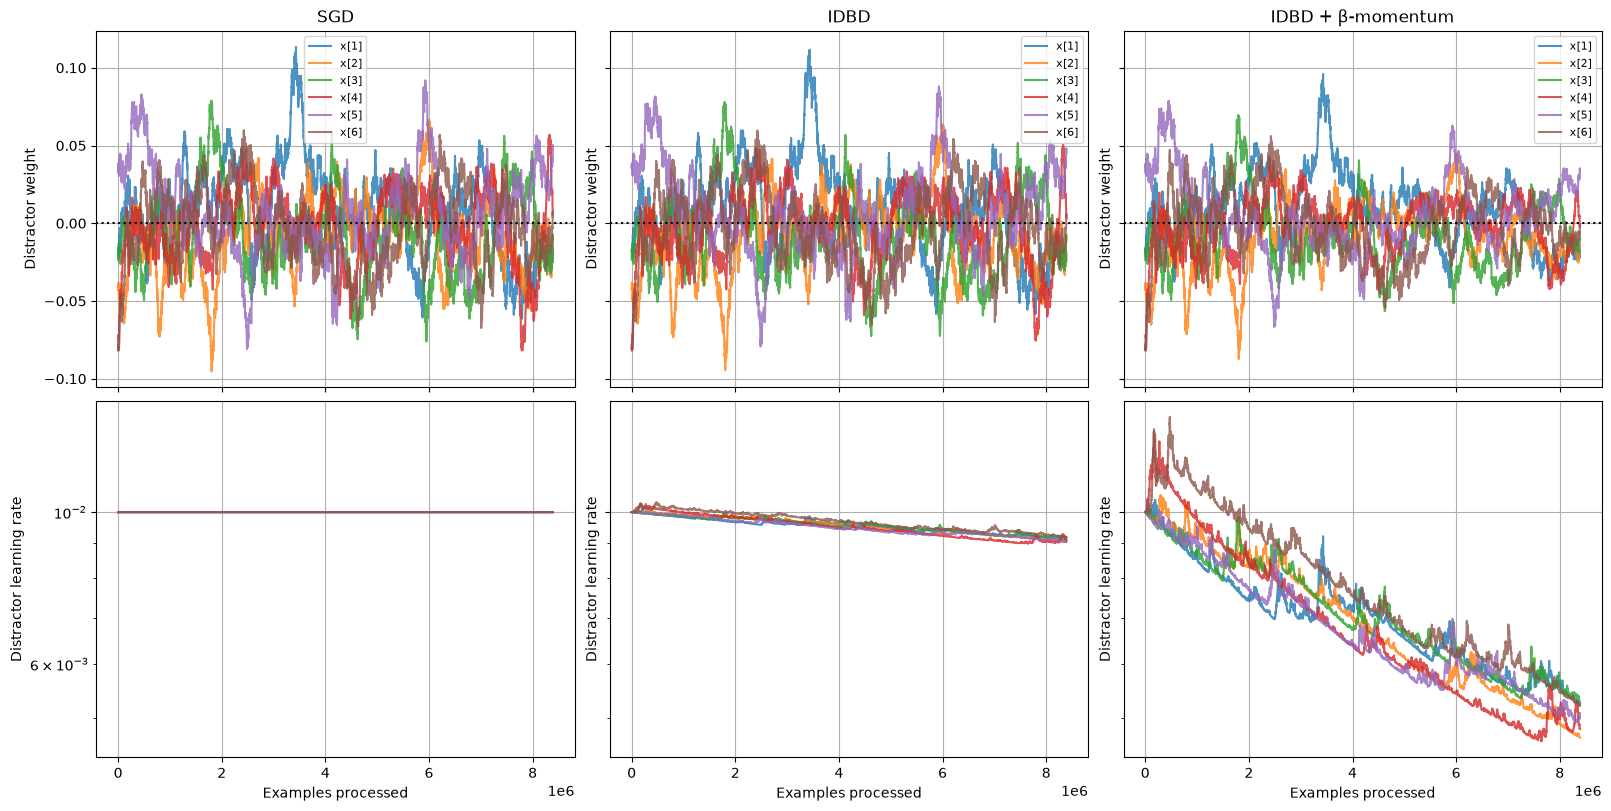

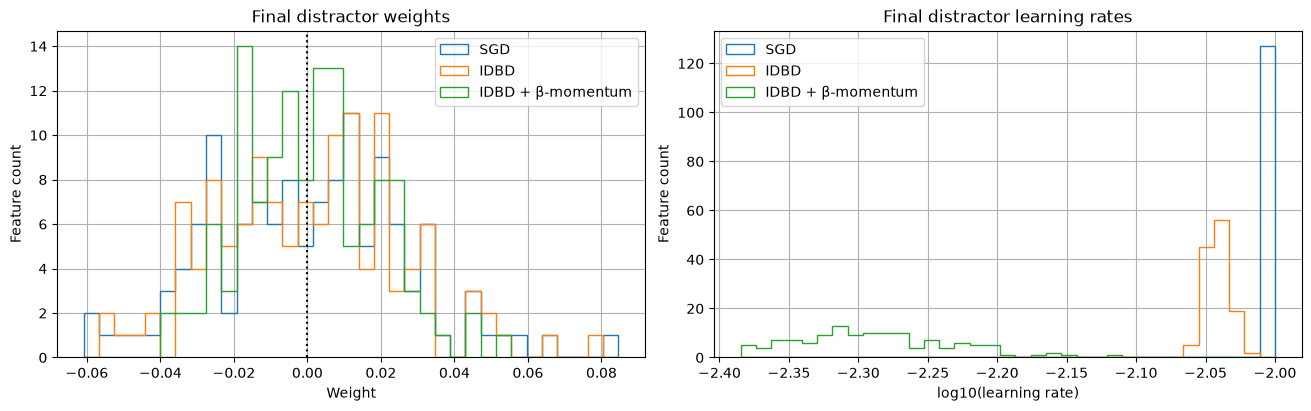

,feature,role,SGD: weight,SGD: lr,IDBD: weight,IDBD: lr,IDBD + β-momentum: weight,IDBD + β-momentum: lr
0,0,useful,0.964651,0.01,0.939953,0.026975,0.968367,0.008178
1,1,distractor,-0.018882,0.01,-0.019276,0.009113,-0.018982,0.005240
2,2,distractor,-0.010592,0.01,-0.011418,0.009042,-0.014154,0.004681
3,3,distractor,-0.007276,0.01,-0.007352,0.009173,-0.005952,0.005267
4,4,distractor,0.007427,0.01,0.005810,0.009091,-0.001460,0.004822
5,5,distractor,0.047023,0.01,0.045227,0.009066,0.033738,0.005067
6,6,distractor,0.004079,0.01,0.002757,0.009202,-0.002002,0.005220
7,7,distractor,-0.022223,0.01,-0.022219,0.009258,-0.018447,0.006117
8,8,distractor,0.022653,0.01,0.019290,0.009167,0.003431,0.005437
9,9,distractor,-0.025141,0.01,-0.024152,0.009122,-0.017344,0.005164


In [14]:
selected_features = np.arange(1, min(INPUT_DIM, 7))
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True,
                         sharey='row', constrained_layout=True)
for column, (name, values) in enumerate(results['trace'].items()):
    for feature in selected_features:
        axes[0, column].plot(results['examples'], values['weights'][:, feature],
                             label=f'x[{feature}]', alpha=0.8)
        axes[1, column].plot(results['examples'], values['rates'][:, feature],
                             label=f'x[{feature}]', alpha=0.8)
    axes[0, column].set_title(name)
    axes[0, column].axhline(0, color='black', linestyle=':')
    axes[0, column].set_ylabel('Distractor weight')
    axes[1, column].set(ylabel='Distractor learning rate', yscale='log',
                        xlabel='Examples processed')
    axes[0, column].legend(fontsize=8)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
all_weights = np.concatenate([v['weights'][-1, 1:] for v in results['trace'].values()])
all_log_rates = np.concatenate([np.log10(v['rates'][-1, 1:]) for v in results['trace'].values()])
weight_bins = np.histogram_bin_edges(all_weights, bins=35)
rate_bins = np.histogram_bin_edges(all_log_rates, bins=35)
for name, values in results['trace'].items():
    axes[0].hist(values['weights'][-1, 1:], bins=weight_bins, histtype='step', label=name)
    axes[1].hist(np.log10(values['rates'][-1, 1:]), bins=rate_bins, histtype='step', label=name)
axes[0].axvline(0, color='black', linestyle=':')
axes[0].set(title='Final distractor weights', xlabel='Weight', ylabel='Feature count')
axes[1].set(title='Final distractor learning rates', xlabel='log10(learning rate)', ylabel='Feature count')
for ax in axes:
    ax.legend()
plt.show()

final_features = pd.DataFrame({'feature': np.arange(INPUT_DIM),
                               'role': ['useful'] + ['distractor'] * (INPUT_DIM - 1)})
for name, values in results['trace'].items():
    final_features[f'{name}: weight'] = values['weights'][-1]
    final_features[f'{name}: lr'] = values['rates'][-1]
display(final_features.head(12))


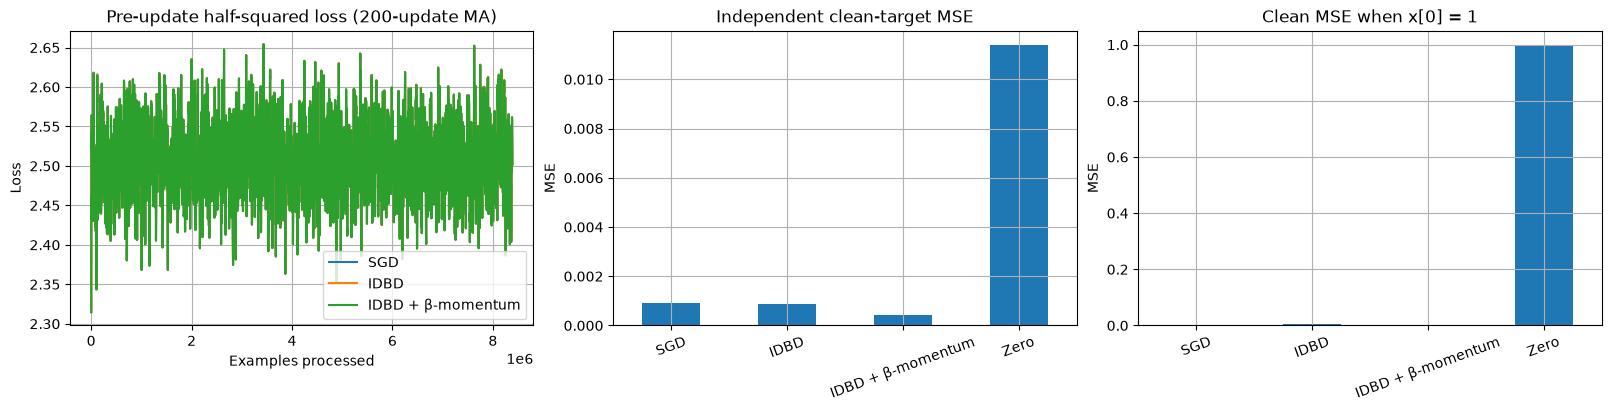

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
for name, values in results['trace'].items():
    axes[0].plot(results['examples'][1:], values['loss_ma_200'][1:], label=name)
axes[0].set(title='Pre-update half-squared loss (200-update MA)',
            xlabel='Examples processed', ylabel='Loss')
axes[0].legend()
for ax, metric, title in zip(axes[1:], ['test_clean_mse', 'test_active_clean_mse'],
                            ['Independent clean-target MSE', 'Clean MSE when x[0] = 1']):
    results['metrics'][metric].plot.bar(ax=ax, rot=20)
    ax.set(title=title, xlabel='', ylabel='MSE')
plt.show()


## Optional: Verstärkung vs. Gedächtniseffekt

Mit `RUN_MATCHED_META_LR = True` wird das Experiment mit frischen Modellen und genau demselben Stream wiederholt. Nur für Momentum gilt dann `momentum_meta_lr = META_LR * (1 - μ)`. Damit ist die Verstärkung für einen konstanten Meta-Gradienten langfristig angeglichen; transient sind beide Regeln weiterhin verschieden. SGD und normales IDBD bleiben unverändert.

Für eine belastbare Aussage mehrere Seeds und Meta-Lernraten testen. Eine Alternative zum Hauptvergleich ist normales IDBD mit `META_LR / (1 - μ)` gegen Momentum mit `META_LR`. Kleinere Lernraten zählen nur zusammen mit kleineren Distraktor-Gewichten und besserem sauberem Testfehler als Verbesserung.

In [16]:
matched_results = None
if RUN_MATCHED_META_LR:
    matched_results = compare(**config, momentum_meta_lr=META_LR * (1 - BETA_MOMENTUM))
    display(pd.concat({'same meta_lr': results['metrics'],
                       'matched long-run gain': matched_results['metrics']},
                      names=['comparison', 'model']))
    plot_overview(matched_results, 'Matched long-run meta-update gain')
else:
    print('Optionaler Vergleich deaktiviert: RUN_MATCHED_META_LR = True setzen und erneut ausführen.')


Optionaler Vergleich deaktiviert: RUN_MATCHED_META_LR = True setzen und erneut ausführen.
